# Principal Component Analysis (PCA) — From First Principles

## 1. Definition and intuition
PCA is an unsupervised linear dimensionality-reduction method. It finds orthogonal directions that capture the greatest possible variance, then projects observations onto the first k directions. It can compress data, reduce noise and support visualization, but high variance is not necessarily the same as predictive importance.

## 2. Mathematics
Center \(X\in\mathbb{R}^{n\times d}\) by subtracting its feature means. The sample covariance matrix is \(S=X_c^TX_c/(n-1)\). PCA directions are eigenvectors \(v_j\) of S, ordered by eigenvalues \(\lambda_1\ge\lambda_2\ge\cdots\ge0\).

The first principal direction solves \(\max_{\|v\|=1} v^TSv\). A Lagrange multiplier gives \(Sv=\lambda v\), so the maximizer is an eigenvector for the largest eigenvalue. Repeating in the orthogonal complement gives subsequent components. Equivalently, use the singular value decomposition \(X_c=U\Sigma V^T\), where right singular vectors are the principal directions and sample explained variances are \(\sigma_j^2/(n-1)\).

## 3. Why it works
For a k-dimensional linear subspace, projection onto the top k eigenvectors maximizes captured sample variance and minimizes total squared reconstruction error among all k-dimensional linear subspaces. This is a result of the eigenvalue ordering / Eckart–Young theorem. It does not promise to preserve labels, nonlinear structure, or low-variance features that may be important for a task.

## 4. Assumptions and failure modes
PCA captures linear directions and is sensitive to feature scale and outliers. Standardize when units or scales should contribute comparably. If features already have meaningful common units, standardizing each to unit variance may alter the problem's intended geometry.

## 5. Dataset and preprocessing

We use the Wine dataset for a compact real-data example. The scaler and PCA are fitted on the training split only. For an unsupervised visualization, labels are used only to color the plot, not to fit PCA.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA as SklearnPCA
from sklearn.metrics import mean_squared_error

SEED = 42
wine = load_wine()
X, y = wine.data, wine.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print("Training shape:", X_train_s.shape)


Training shape: (133, 13)


## 6. PCA from scratch

We use SVD rather than explicitly forming the covariance matrix. SVD is generally more numerically robust, especially when some features are nearly collinear. Component signs are arbitrary: a component vector and its negation describe the same axis.

In [2]:
def fit_pca_svd(X, n_components):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or X.shape[0] < 2 or X.shape[1] == 0:
        raise ValueError("X must be 2D with at least two samples and one feature")
    if not 1 <= n_components <= min(X.shape):
        raise ValueError("n_components must be between 1 and min(n_samples, n_features)")
    if not np.isfinite(X).all():
        raise ValueError("X must contain finite values")
    mean = X.mean(axis=0)
    Xc = X - mean
    U, singular_values, Vt = np.linalg.svd(Xc, full_matrices=False)
    all_variances = singular_values**2 / (len(X) - 1)
    components = Vt[:n_components]
    explained = all_variances[:n_components]
    total_variance = all_variances.sum()
    ratios = explained / total_variance if total_variance > 0 else np.zeros_like(explained)
    return {
        "mean": mean,
        "components": components,
        "explained_variance": explained,
        "explained_variance_ratio": ratios,
        "all_explained_variance_ratio": all_variances / total_variance if total_variance > 0 else all_variances
    }

def pca_transform(X, fitted):
    return (np.asarray(X) - fitted["mean"]) @ fitted["components"].T

def pca_inverse_transform(Z, fitted):
    return np.asarray(Z) @ fitted["components"] + fitted["mean"]

k = 2
pca = fit_pca_svd(X_train_s, n_components=k)
Z_train = pca_transform(X_train_s, pca)
Z_test = pca_transform(X_test_s, pca)
X_reconstructed = pca_inverse_transform(Z_test, pca)
print("Explained variance ratios:", pca["explained_variance_ratio"])
print("Total variance retained by first", k, "components:", pca["explained_variance_ratio"].sum())
print("Held-out reconstruction MSE:", mean_squared_error(X_test_s, X_reconstructed))


Explained variance ratios: [0.35749925 0.19209251]
Total variance retained by first 2 components: 0.549591754414216
Held-out reconstruction MSE: 0.4693018797022138


## 7. Visualize the projection

PCA is not trained on labels. Coloring the projected observations by class can help inspect structure, but visual separation is not itself a proof of predictive utility.

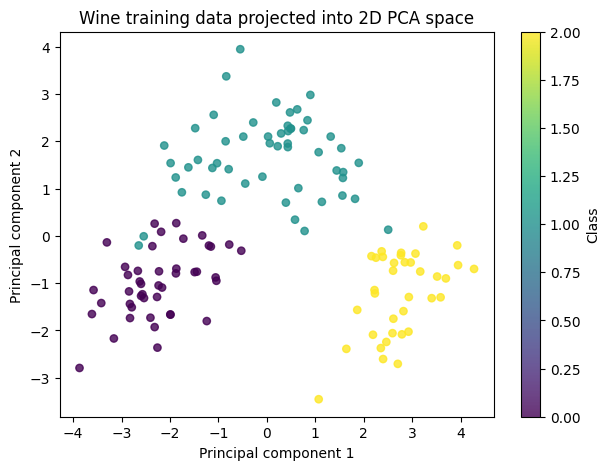

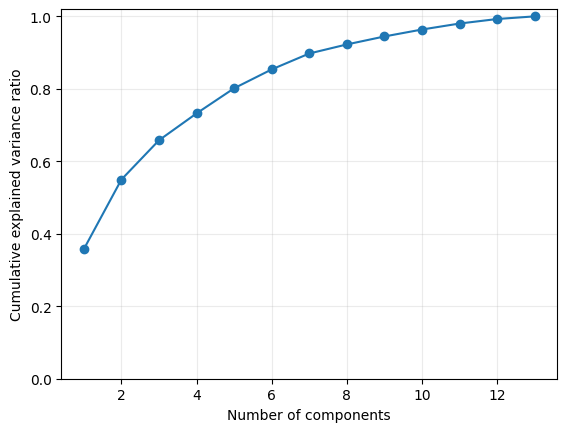

In [3]:
plt.figure(figsize=(7, 5))
plt.scatter(Z_train[:, 0], Z_train[:, 1], c=y_train, cmap="viridis", s=28, alpha=0.8)
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.title("Wine training data projected into 2D PCA space")
plt.colorbar(label="Class")
plt.show()

plt.plot(np.arange(1, len(pca["all_explained_variance_ratio"])+1),
         np.cumsum(pca["all_explained_variance_ratio"]), marker="o")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance ratio")
plt.ylim(0, 1.02)
plt.grid(True, alpha=0.25)
plt.show()


## 8. Compare with scikit-learn

Compare explained variances and reconstruction error, not raw component entries, because eigenvector signs are arbitrary. We use full SVD for a comparable exact solution.

In [4]:
sk_pca = SklearnPCA(n_components=2, svd_solver="full").fit(X_train_s)
Z_sk = sk_pca.transform(X_test_s)
X_sk_recon = sk_pca.inverse_transform(Z_sk)
print("Scratch explained variance:", pca["explained_variance"])
print("sklearn explained variance:", sk_pca.explained_variance_)
print("Scratch reconstruction MSE:", mean_squared_error(X_test_s, X_reconstructed))
print("sklearn reconstruction MSE:", mean_squared_error(X_test_s, X_sk_recon))
assert np.allclose(pca["explained_variance"], sk_pca.explained_variance_, rtol=1e-8, atol=1e-8)
assert np.allclose(mean_squared_error(X_test_s, X_reconstructed),
                   mean_squared_error(X_test_s, X_sk_recon), rtol=1e-7)
assert np.allclose(pca["components"] @ pca["components"].T, np.eye(2), atol=1e-8)


Scratch explained variance: [4.68269845 2.51612082]
sklearn explained variance: [4.68269845 2.51612082]
Scratch reconstruction MSE: 0.4693018797022138
sklearn reconstruction MSE: 0.4693018797022138


## 9. Hyperparameters and best practices

- `n_components`: number of retained directions. Choose based on a variance target, downstream validation, compression needs, or interpretability.
- `svd_solver`: exact full SVD is robust but can be costly; randomized methods approximate top components for large matrices.
- Standardize when scale differences should not dominate.
- Fit scaling and PCA only on training data; put both in a pipeline for supervised experiments.
- Do not infer that a low-variance component is useless for prediction; validate the downstream task.
- PCA is linear. Consider nonlinear manifold methods only when the problem and scale justify them.

## 10. Complexity

Let n be sample count, d feature count, k retained components, and m new samples. Full exact SVD has time complexity roughly \(O(\min(nd^2,n^2d))\); constants and memory depend on matrix shape and solver. Dense input storage is \(O(nd)\), while components take \(O(kd)\). Transforming m observations costs \(O(mdk)\); inverse projection also costs \(O(mdk)\).

For millions of samples, randomized or incremental PCA may be preferable. Process batches, avoid duplicate copies of the full dataset, and use float32 if numerical accuracy permits. Exact dense PCA may be limited by memory even before compute becomes the bottleneck.

## 11. Optional PyTorch GPU SVD

GPU SVD can help for large dense matrices that fit in device memory. This is a separate optional demonstration; its output will use GPU tensors when CUDA is available.

In [5]:
try:
    import torch
    if torch.cuda.is_available():
        dev = torch.device("cuda")
        Xt = torch.as_tensor(X_train_s, dtype=torch.float32, device=dev)
        Xc = Xt - Xt.mean(dim=0, keepdim=True)
        U, S, Vh = torch.linalg.svd(Xc, full_matrices=False)
        var = S**2 / (Xt.shape[0] - 1)
        print("GPU:", torch.cuda.get_device_name(0))
        print("GPU first two explained variance ratios:", (var[:2] / var.sum()).cpu().numpy())
    else:
        print("CUDA unavailable; GPU PCA skipped.")
except ImportError:
    print("PyTorch is optional and is not installed.")


CUDA unavailable; GPU PCA skipped.


## 12. Correctness tests and synthesis

PCA finds the linear subspace that preserves the most variance (equivalently, minimizes reconstruction error for a fixed number of components). SVD computes that subspace efficiently and robustly. The number of retained components is a modeling choice, not a universal constant.

In [6]:
assert np.isfinite(Z_test).all()
assert Z_test.shape == (len(X_test_s), 2)
assert np.all(pca["explained_variance"] >= 0)
assert np.all(np.diff(pca["all_explained_variance_ratio"]) <= 1e-8)
try:
    fit_pca_svd(np.array([1, 2, 3]), 1)
except ValueError:
    pass
else:
    raise AssertionError("Expected invalid input dimensionality to raise")
print("All PCA checks passed.")


All PCA checks passed.
